In [ ]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 7
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

Let (𝑋, 𝑌 ) have the joint density:

$$
f_{XY} (x,y) =  x + y, \ \ \ \ \ 0\leq x \leq 1, 0\leq y \leq 1
$$

**Hand in.** Figure 1, three panels: a filled contour or heatmap of the joint density, the two marginals with
analytic and numerical curves overlaid, and the conditional at 𝑥 = 0.3.

**Check yourself.** 

𝐸[𝑋] = 𝐸[𝑌 ] = 7/12 = 0.583333.
 
𝐸[𝑋𝑌 ] = 1/3. 

Var(𝑋) = 11/144 = 0.0763889.

Cov(𝑋, 𝑌 ) = −1/144 = −0.00694444. 

𝜌 = −1/11 = −0.0909091. 

The marginal is 𝑓𝑋(𝑥) = 𝑥 + 1/2, so 𝑓𝑋(0.3) = 0.8.

### 1. Verify by hand that this is a valid density, then confirm it numerically with a 2D quadrature.

*To verify by hand, a valid density must have volume = 1*

$$ \int^1_0 \int^1_0 (x+y) \, dxdy $$

$$ \int^1_0 \left[ \frac{x^2}{2} + y \right]^1_0 \, dy = \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \boxed{ \left[ \frac{1}{2} + \frac{y^2}{2} \right]^1_0 \,  = \frac{1}{2} + \frac{1}{2} = 1} $$

In [95]:
# Verifying numerically via 2D quadrature

from scipy.integrate import dblquad

def f_xy(y, x):
  return x + y

val, err = dblquad(
    f_xy,
    0,
    1,  
    lambda x: 0,
    lambda x: 1,
)

print(f"Double integral is evaluated to:\t{val}\n" + 
      f"Estimated error:\t\t\t{err:.3e}")

Double integral is evaluated to:	1.0
Estimated error:			1.663e-14


### 2. Derive both marginals by hand. Confirm each numerically by integrating the joint density over the other variable on a grid, and overlay the numerical marginal on the analytic on

*Marginal Density of X*

$$ f_X(x) = \int^1_0 (x + y) \, dy = \left[ xy + \frac{y^2}{2} \right]^1_0 $$

$$ \boxed{f_X(x) = x + \frac{1}{2}} $$

___

*Marginal Density of Y*

$$ f_Y(y) = \int^1_0 (x + y) \, dx = \left[ \frac{x^2}{2} + xy  \right]^1_0 $$

$$ \boxed{f_Y(y) = x + \frac{1}{2}} $$

In [96]:
# grid for x and y
grid = np.linspace(0, 1, 200)
X, Y = np.meshgrid(grid, grid, indexing='ij')

# joint pdf
F_xy = X + Y

# numerical marginals using np.trapezoid
f_x_num = np.trapezoid(F_xy, grid, axis=1)
f_y_num = np.trapezoid(F_xy, grid, axis=0)

# analytic marginals
f_x_analytic = grid + 0.5
f_y_analytic = grid + 0.5

# fig 1 being made
fig1, axes = plt.subplots(1, 3, figsize=(15, 4))

hm = axes[0].pcolormesh(X, Y, Z, cmap="viridis", shading="auto")

fig1.colorbar(hm, ax=axes[0], label=r"$f_{XY}(x, y)$")
axes[0].set_title("Continuous Heatmap ")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].set_aspect("equal")

# Marginal of X
axes[1].plot(
    grid, f_x_analytic, label='Analytic $f_X(x) = x + 0.5$', linewidth=1.5, color='b'
)
axes[1].plot(
    grid[::10],
    f_x_num[::10],
    'o',
    # color='r',
    label='X (Numerical)',
    markersize=3,
)

# Marginal of Y
axes[1].plot(
    grid, f_y_analytic, label='Analytic $f_Y(y) = y + 0.5$', linewidth=1, color='r'
)
axes[1].plot(
    grid[::10],
    f_y_num[::10],
    'o',
    label='Y (Numerical)',
    markersize=2,
)
axes[1].set_title('Marginal Density of $X$ and $Y$')
axes[1].set_xlabel('$x$ or $y$')
axes[1].set_ylabel('$f_X(x)$ or $f_Y(y)$')
axes[1].set_ylim(0, 1.7)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig1.tight_layout()
plt.close(fig1)

### 3. Derive the conditional density of 𝑌 given 𝑋 = 𝑥. Evaluate it at 𝑥 = 0.3 and plot it. Confirm it integrates to 1.

*Conditional Density of 𝑌 given 𝑋 = 𝑥*

$$ f_{Y|X}(y|x) = \frac{x+y}{x+0.5} $$

___

*At 𝑥 = 0.3:*

$$ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.3+0.5} =  \frac{0.3+y}{0.8} $$

$$ \text{at y=0:} \ \ \ f_{Y|X}(0|0.3) $$

$$ \text{at y=1:} \ \ \ f_{Y|X}(1|0.3) $$

___

*Conditional Density integrating to 1*

$$ \int^1_0 f_{Y|X}(y|0.3) \, dy = \int^1_0 \frac{x+y}{x+0.5} \, dy $$

$$ \int^1_0 \frac{x+y}{x+0.5} \, dy = \frac{1}{0.8} \left[ 0.3y + \frac{y^2}{2}\right]^1_0 = $$

$$\boxed{\frac{1}{0.8}(0.3+\frac{1}{2}) = 1}$$

Integral of f_(Y|X)(y | 0.3):	0.9999999999999999
Estimated error:		1.110e-14
At x=0.3, conditional density does still integrate to 1.


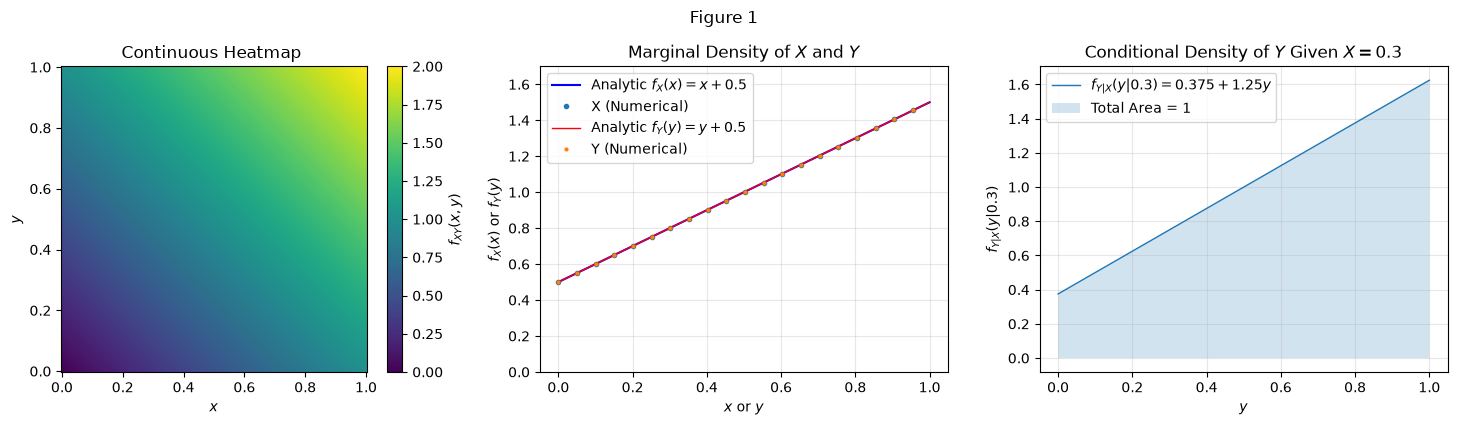

In [97]:
from scipy.integrate import quad

x_val = 0.3
f_y_given_x = lambda y: (x_val + y) / (x_val + 0.5)

area, err = quad(f_y_given_x, 0, 1)

print(f"Integral of f_(Y|X)(y | 0.3):\t{area}\n" + f"Estimated error:\t\t{err:.3e}")
print(f"At x=0.3, conditional density does still integrate to 1.")

# 2. conditional density at x=0.3
y = np.linspace(0, 1, 200)
pdf_vals = f_y_given_x(y)

axes[2].plot(y, pdf_vals, linewidth=1, label=r"$f_{Y|X}(y | 0.3) = 0.375 + 1.25y$", markersize=10)
axes[2].fill_between(y, pdf_vals, alpha=0.2, label="Total Area = 1")
axes[2].set_title("Conditional Density of $Y$ Given $X = 0.3$")
axes[2].set_xlabel("$y$")
axes[2].set_ylabel("$f_{Y|X}(y | 0.3)$")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

fig1.suptitle('Figure 1', y=1.05)
fig1

*Continuous Heatmap*

The continuous heatmap provides a smooth interpretation of the outcomes of the probability. It shows a negative correlation between x and y, where as one becomes a higher number, it's likely that the other is lower. This is found as the gradient

*Marginal Density of X and Y*

Both x and y form the same linear line that have a positive slope, both in the analytical and numerical plots. The analytic and numerical values of so match exactly, that all 4 plots (the analytic and numerical marginals of x and y), lay on top of each other.

*Conditional Density of Y Given X = 0.3*

When providing X = 0.3, it creates essentially a slice from the heatmap and provides a density that is more easily represneted by a line on a 2d graph. As X is fixed to a smaller value, Y is shown to be pulled upward and thus creates a steeper slope in the graph.

### 4. Compute 𝐸[𝑋], 𝐸[𝑌], 𝐸[𝑋𝑌], Var(𝑋), Cov(𝑋, 𝑌) and the correlation coefficient, all by hand, and verify each by quadrature.

*Computing 𝐸[𝑋] and 𝐸[𝑌]* 

$$
\begin{align*}
E[X] &= \int_0^1 x \left(x + \frac{1}{2}\right) dx \\
     &= \int_0^1 \left(x^2 + \frac{1}{2}x\right) dx \\
     &= \left[ \frac{x^3}{3} + \frac{x^2}{4} \right]_0^1 \\
     &= \frac{1}{3} + \frac{1}{4} = \boxed{\frac{7}{12} = 0.583}
\end{align*} \\
\text{Due to symmetry: }\ \boxed{E[Y] = \frac{7}{12} = 0.583}
$$

___

*Computing 𝐸[𝑋𝑌]*

$$
\begin{align*}
E[XY] &= \int_0^1 \int_0^1 xy(x + y) \, dx \, dy \\
      &= \int_0^1 \left[ \frac{x^3}{3}y + \frac{x^2}{2}y^2 \right]_{x=0}^{x=1} dy \\
      &= \int_0^1 \left( \frac{1}{3}y + \frac{1}{2}y^2 \right) dy \\
      &= \left[ \frac{y^2}{6} + \frac{y^3}{6} \right]_0^1 \\
      &= \boxed{\frac{1}{6} + \frac{1}{6} = \frac{1}{3} = 0.333}
\end{align*}
$$

___

*Computing Var(𝑋)*

$$
\begin{align*}
E[X^2] &= \int_0^1 x^2 \left(x + \frac{1}{2}\right) dx \\
       &= \left[ \frac{x^4}{4} + \frac{x^3}{6} \right]_0^1 \\ 
       &= \frac{1}{4} + \frac{1}{6} = \frac{5}{12}
\end{align*}
\\
\\
\begin{align*}
Var(X) &= E[X^2] - (E[X])^2 \\
&= \frac{5}{12} - \left(\frac{7}{12}\right)^2 \\
&= \frac{60 - 49}{144} \\
&= \boxed{\frac{11}{144}}
\end{align*}
$$

___

*Computing Cov(𝑋, 𝑌)*

$$
\begin{align*}
Cov(X, Y) &= E[XY] - E[X]E[Y] \\
          &= \frac{1}{3} - \left(\frac{7}{12}\right)\left(\frac{7}{12}\right) \\
          &= \boxed{\frac{48 - 49}{144} = -\frac{1}{144}}
\end{align*}
$$

In [98]:
def f_xy(y, x):
  return x + y

#exact values
ex = 7/12
ey = 7/12
exy = 1/3
varx = 11/144
covxy = -1/144

EX, _ = dblquad(lambda y, x: x * f_xy(y, x), 0, 1, 0, 1)
EY, _ = dblquad(lambda y, x: y * f_xy(y, x), 0, 1, 0, 1)
EXY, _ = dblquad(lambda y, x: x * y * f_xy(y, x), 0, 1, 0, 1)
EX2, _ = dblquad(lambda y, x: (x**2) * f_xy(y, x), 0, 1, 0, 1)
EY2, _ = dblquad(lambda y, x: (y**2) * f_xy(y, x), 0, 1, 0, 1)

VarX = EX2 - EX**2
CovXY = EXY - EX * EY

print(f"E[X]      = {EX:.6f}\t | Exact: {ex:.6f}\t | %Error: {(abs(EX-ex)/ex)*100:.6e}")
print(f"E[Y]      = {EY:.6f}\t | Exact: {ey:.6f}\t | %Error: {(abs(EY-ey)/ey)*100:.6e}")
print(f"E[XY]     = {EXY:.6f}\t | Exact: {exy:.6f}\t | %Error: {(abs(EXY-exy)/exy)*100:.6e}")
print(f"Var(X)    = {VarX:.6f}\t | Exact: {varx:.6f}\t | %Error: {(abs(VarX-varx)/varx)*100:.6e}")
print(f"Cov(X, Y) = {CovXY:.6f}\t | Exact: {corxy:.6f}\t | %Error: {(abs(CovXY-covxy)/covxy)*100:.6e}")

E[X]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[Y]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[XY]     = 0.333333	 | Exact: 0.333333	 | %Error: 3.330669e-14
Var(X)    = 0.076389	 | Exact: 0.076389	 | %Error: 7.266914e-14
Cov(X, Y) = -0.006944	 | Exact: -0.006944	 | %Error: -2.747802e-12


### 5. Generate 10<sup>6</sup> samples from this joint density by rejection sampling, and confirm your sample statistics against the analytic values with standard errors. State your acceptance rate and explain how you chose the bounding constant.

In [99]:
N_target = n[6]
M = 2.0

# Generate samples in batches until we collect exactly 10^6 accepted pairs
x_accepted = []
y_accepted = []
total_proposed = 0

while sum(len(chunk) for chunk in x_accepted) < N_target:
  batch_size = 500_000
  x_cand = rng_1.uniform(0.0, 1.0, size=batch_size)
  y_cand = rng_1.uniform(0.0, 1.0, size=batch_size)
  u = rng_1.uniform(0.0, 1.0, size=batch_size)

  # Acceptance condition: u <= f(x, y) / (M * g(x, y)) = (x + y) / 2
  accept_mask = u <= (x_cand + y_cand) / M

  x_accepted.append(x_cand[accept_mask])
  y_accepted.append(y_cand[accept_mask])
  total_proposed += batch_size

# Trim to exact N_target = 10^6 samples (and adjust total_proposed proportionally)
X = np.concatenate(x_accepted)[:N_target]
Y = np.concatenate(y_accepted)[:N_target]
total_accepted_all = sum(len(chunk) for chunk in x_accepted)
empirical_acceptance_rate = total_accepted_all / total_proposed

# --- Sample Statistics ---
mean_X = np.mean(X)
mean_Y = np.mean(Y)
mean_XY = np.mean(X * Y)
var_X = np.var(X, ddof=1)
var_Y = np.var(Y, ddof=1)
cov_XY = np.cov(X, Y, ddof=1)[0, 1]
corr_XY = np.corrcoef(X, Y)[0, 1]

# --- Standard Errors (SE) ---
# SE of sample means: s / sqrt(N)
se_mean_X = np.std(X, ddof=1) / np.sqrt(N_target)
se_mean_Y = np.std(Y, ddof=1) / np.sqrt(N_target)
se_mean_XY = np.std(X * Y, ddof=1) / np.sqrt(N_target)

# SE of sample variance: sqrt(mu_4 - sigma^4) / sqrt(N)
se_var_X = np.sqrt(np.mean((X - mean_X) ** 4) - var_X**2) / np.sqrt(N_target)
se_var_Y = np.sqrt(np.mean((Y - mean_Y) ** 4) - var_Y**2) / np.sqrt(N_target)

# SE of sample covariance: sqrt(E[(X - mu_X)^2 (Y - mu_Y)^2] - Cov^2) / sqrt(N)
prod_dev = (X - mean_X) * (Y - mean_Y)
se_cov_XY = np.sqrt(np.mean(prod_dev**2) - cov_XY**2) / np.sqrt(N_target)

# SE of sample correlation: (1 - r^2) / sqrt(N - 2)
se_corr_XY = (1 - corr_XY**2) / np.sqrt(N_target - 2)

print(f"Empirical Acceptance Rate: {empirical_acceptance_rate:.5f} (Theoretical: 0.50000)\n")
print(f"{'Statistic':<12} | {'Sample Est.':<12} | {'Std. Error':<12} | {'Analytic':<12}")
print("-" * 56)
print(f"{'E[X]':<12} | {mean_X:<12.6f} | {se_mean_X:<12.6f} | {7/12:<12.6f}")
print(f"{'E[Y]':<12} | {mean_Y:<12.6f} | {se_mean_Y:<12.6f} | {7/12:<12.6f}")
print(f"{'E[XY]':<12} | {mean_XY:<12.6f} | {se_mean_XY:<12.6f} | {1/3:<12.6f}")
print(f"{'Var(X)':<12} | {var_X:<12.6f} | {se_var_X:<12.6f} | {11/144:<12.6f}")
print(f"{'Var(Y)':<12} | {var_Y:<12.6f} | {se_var_Y:<12.6f} | {11/144:<12.6f}")
print(f"{'Cov(X, Y)':<12} | {cov_XY:<12.6f} | {se_cov_XY:<12.6f} | {-1/144:<12.6f}")

Empirical Acceptance Rate: 0.50001 (Theoretical: 0.50000)

Statistic    | Sample Est.  | Std. Error   | Analytic    
--------------------------------------------------------
E[X]         | 0.583254     | 0.000276     | 0.583333    
E[Y]         | 0.583221     | 0.000276     | 0.583333    
E[XY]        | 0.333242     | 0.000236     | 0.333333    
Var(X)       | 0.076362     | 0.000076     | 0.076389    
Var(Y)       | 0.076363     | 0.000076     | 0.076389    
Cov(X, Y)    | -0.006924    | 0.000075     | -0.006944   


### 6. The correlation is small and negative. Explain in two sentences what in the shape of this density makes 𝑋 and 𝑌 pull against each other.

The density $f_{XY}(x, y) = x + y$ grows linearly as either x or y increases, and thus it lowers the probability mass near (0, 0) where both variables would be small together, while keeping high, uniform contour bands along the anti-diagonal lines $x + y = c$ where one variable is large and the other is small. As a result, when $X$ is small, $Y$ is strongly pushed toward larger values to keep $x + y$ large, causing the two variables to slightly pull against each other on average (which can be better seen in the heat map).

## Step 2

### Question 1

$\text{Let } X \sim U(-1, 1) \text{ and } Y = X^{2}$

$f_{X}(x)=\frac{1}{1-(-1)}=\frac{1}{2}$

<br>

$\mathbb{E}[X] = \int_{-1}^{+1} \frac{1}{2} x\ dx$

$\hspace{2.4em} = \frac{1}{4} [x^{2}]_{-1}^{+1}$

$\hspace{2.4em} = \frac{1}{4} [0]$

$\hspace{2.4em} = 0$

<br>

$\mathbb{E}[Y] = \int_{-1}^{+1} \frac{1}{2} x^{2}\ dx$

$\hspace{2.3em} = \frac{1}{6} [x^{3}]_{-1}^{+1}$

$\hspace{2.3em} = \frac{1}{6} [2]_{-1}^{+1}$

$\hspace{2.3em} = \frac{1}{3}$

<br>

$\mathbb{E}[XY] = \int_{-1}^{+1} \frac{1}{2} x^{3}\ dx$

$\hspace{3.2em} = \frac{1}{8} [x^{4}]_{-1}^{+1}$

$\hspace{3.2em} = \frac{1}{8} [0]$

$\hspace{3.2em} = 0$

<br>

$\text{Cov}(X, Y) = \mathbb{E}[XY] - \mathbb{E}[X]\mathbb{E}[Y]$

$\hspace{5em} = (0) - (0)(\frac{1}{3})$

$\hspace{5em} = 0$

### Question 2

In [88]:
X = rng_2.uniform(-1, 1, size=n[7])
Y = X ** 2
[varx, cov], [_, vary] = ml.sample_mean_cov(np.stack((X, Y), axis=1))[1]
corr = cov / np.sqrt(varx * vary)
se_r = np.sqrt((1 - corr**2) / (n[7] - 2))

print(f"Cov(X,Y) = {cov:.5f}\n" +
      f"Var(X) = {varx:.5f}, Var(Y) = {vary:.5f}\n")

print(f"Corr(X,Y) = {corr:.5f}\n" +
      f"SE(Corr(X,Y)) = {se_r:.5f}")

Cov(X,Y) = -0.00007
Var(X) = 0.33339, Var(Y) = 0.08892

Corr(X,Y) = -0.00041
SE(Corr(X,Y)) = 0.00032


### Question 3

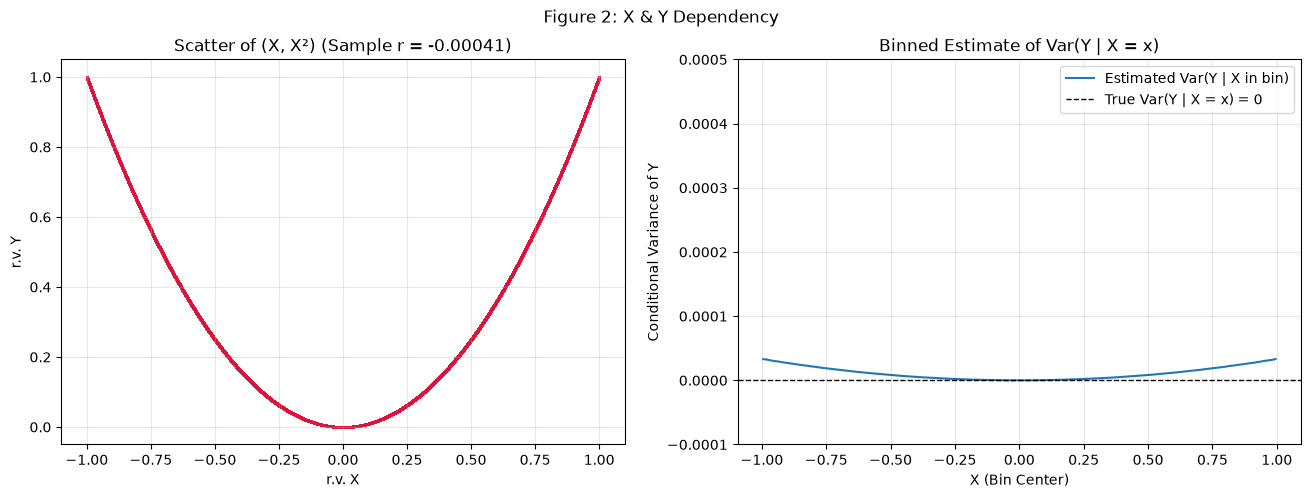

Bin width h = 0.0100

Max binned variance (L_inf): 3.3195e-05
RMS binned variance (L_2):   1.4907e-05
Mean binned variance:        1.1112e-05 (0.0125% of Var(Y))


In [ ]:
binned_var, bin_edges, _ = stats.binned_statistic(X, Y, statistic=lambda y: np.var(y, ddof=1), bins=200)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(X, Y, color='crimson', marker='o', s=1)
axes[0].set_title(f"Scatter of (X, X\u00b2) (Sample r = {corr:.5f})")
axes[0].set_xlabel("r.v. X")
axes[0].set_ylabel("r.v. Y")
axes[0].grid(True, alpha=0.3)

axes[1].plot(bin_centers, binned_var, label="Estimated Var(Y | X in bin)")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="True Var(Y | X = x) = 0")
axes[1].set_title("Binned Estimate of Var(Y | X = x)")
axes[1].set_xlabel("X (Bin Center)")
axes[1].set_ylabel("Conditional Variance of Y")
axes[1].set_ylim(-0.0001, 0.0005)  # Shows how close to 0 it is relative to Var(Y) ≈ 0.089
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("Figure 2: X & Y Dependency")

plt.show()

h = 2.0 / len(binned_var)

max_var = np.max(binned_var)  # L-infinity norm
rms_var = np.sqrt(np.mean(binned_var**2))  # Normalized L2 norm
mean_var = np.mean(binned_var)  # Average E[Var(Y | X in bin)]
unexplained_ratio = mean_var / np.var(Y)  # Fraction of total Var(Y) = 4/45

print(f"Bin width h = {h:.4f}\n")

print(f"Max binned variance (L_inf): {max_var:.4e}")
print(f"RMS binned variance (L_2):   {rms_var:.4e}")
print(f"Mean binned variance:        {mean_var:.4e} ({unexplained_ratio:.4%} of Var(Y))")

### Question 4

The correlation coefficent measures the strength and direction of two variables linear relationship, meaning that it fails to measure nonlinear relationships such as this, where Y at points has negative slope when X's slope is positive.

### Question 5

In [97]:
data=np.random.multivariate_normal([0, 0], [[1, 0], [0, 1]], size=n[7])
x, y = data[:, 0], data[:, 1]

bins = 40
range_lims = [[-4, 4], [-4, 4]]

# Empirical joint density f_{X,Y}(x, y)
joint_hist, x_edges, y_edges = np.histogram2d(
    x, y, bins=bins, range=range_lims, density=True
)

# Empirical marginal densities f_X(x) and f_Y(y)
x_hist, _ = np.histogram(x, bins=x_edges, density=True)
y_hist, _ = np.histogram(y, bins=y_edges, density=True)

# Product of marginals: f_X(x) * f_Y(y)
prod_marginals = np.outer(x_hist, y_hist)

# quantify agreement
abs_diff = np.abs(joint_hist - prod_marginals)
mae = np.mean(abs_diff)
rmse = np.sqrt(np.mean((joint_hist - prod_marginals) ** 2))
max_err = np.max(abs_diff)

# Bin area (dx * dy) for integral-based metrics
dx = x_edges[1] - x_edges[0]
dy = y_edges[1] - y_edges[0]

# Total Variation Distance (TVD): 0.5 * \iint |f_{X,Y} - f_X f_Y| dx dy
tvd = 0.5 * np.sum(abs_diff) * dx * dy

# Kullback-Leibler (KL) Divergence / Mutual Information: D_KL(P_{X,Y} || P_X P_Y)
mask = (joint_hist > 0) & (prod_marginals > 0)
kl_div = np.sum(joint_hist[mask] * np.log(joint_hist[mask] / prod_marginals[mask])) * dx * dy

# Sample Pearson correlation
sample_corr = stats.pearsonr(x, y)[0]

print(f"Sample Pearson r:                     {sample_corr:.6f}")
print(f"Mean Absolute Error (MAE):            {mae:.6f}")
print(f"Root Mean Squared Error (RMSE):       {rmse:.6f}")
print(f"Max Absolute Error:                   {max_err:.6f}")
print(f"Total Variation Distance (TVD):       {tvd:.6f}")
print(f"KL Divergence (Mutual Information):   {kl_div:.6e} nats")

Sample Pearson r:                     0.000033
Mean Absolute Error (MAE):            0.000099
Root Mean Squared Error (RMSE):       0.000204
Max Absolute Error:                   0.001587
Total Variation Distance (TVD):       0.003175
KL Divergence (Mutual Information):   7.775888e-05 nats


### Question 6

Because a jointly Gaussian distribution is completely determined by its mean vector and covariance matrix, zero covariance causes the joint PDF to factor directly into the product of its marginal densities, guaranteeing independence. In general, however, correlation only captures linear relationships, meaning non-Gaussian variables can have zero covariance while remaining strongly dependent through nonlinear patterns (such as Y = X^2 in questions 1-4 of this step). This makes the Gaussian assumption load-bearing because it allows Kalman filters, linear estimators and other such methods high degrees of statistical accuracy using only second-order properties (mean/covariance), while preventing unfeasible computation hurdles (such as tracking entire distributions).

## Step 3

## Step 4

### 1. State and derive the two transformation rules: for $y = 𝐴x +b$, the mean is $𝐴𝜇_𝑥 +b$ and the covariance is $𝐴Σ_𝑥𝐴^𝑇$. The covariance derivation is three lines. Write them.

#### The two transformation rules:

For $y = 𝐴x +b$: 

The mean is $𝐴𝜇_𝑥 +b$

The covariance is $𝐴Σ_𝑥𝐴^𝑇$
___

#### Derivation for the mean

$$\begin{aligned}
\mu _y &= \mathbb{E}[y] \\
       &= \mathbb{E}[Ax + b] \\
       &= A\mathbb{E}[x] + b \\
       &= A\mu_x + b
\end{aligned}$$

___

#### Derivation for the covarience in three lines

$$\begin{aligned}
\Sigma _y &= \mathbb{E}\left[(y - \mu _y)(y - \mu _y)^T\right] \\
          &= \mathbb{E}\left[A(x - \mu _x)(x - \mu _x)^T A^T\right] \\
          &= A\,\mathbb{E}\left[(x - \mu _x)(x - \mu _x)^T\right]A^T = A\Sigma_x A^T
\end{aligned}$$

### 2. Take $𝜇_𝑥 = [1, −2]^𝑇$ and $Σ𝑥 = \begin{bmatrix}4 & 2\\ 2 & 4\end{bmatrix}$, and the matrix $ A = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} $. Compute 𝜇𝑦 and Σ𝑦 by hand, then verify both from 10<sup>6</sup> simulated samples with standard errors. 

#### Computing $\mu_y$ and $\Sigma_y$ by Hand:

Given $x \sim \mathcal{N}(\mu_x, \Sigma_x)$ and the linear transformation $y = Ax$, the transformed mean and covariance are:

$$
\mu_y = A\mu_x, \qquad \Sigma_y = A\Sigma_x A^T
$$

*Mean ($\mu_y$)*

$$
\mu_y = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} \begin{bmatrix} 1 \\ -2 \end{bmatrix} 
= \begin{bmatrix} 1(1) + 2(-2) \\ 0(1) + 1(-2) \\ 1(1) - 1(-2) \end{bmatrix} 
= \boxed{\begin{bmatrix} -3 \\ -2 \\ 3 \end{bmatrix}}
$$

*Covariance ($\Sigma_y$)*

Compute $A\Sigma_x$:

$$
A\Sigma_x = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} 
= \begin{bmatrix} 1(4)+2(2) & 1(2)+2(4) \\ 0(4)+1(2) & 0(2)+1(4) \\ 1(4)-1(2) & 1(2)-1(4) \end{bmatrix} 
= \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 & -2 \end{bmatrix}
$$

Multiply by $A^T$:

$$
\Sigma_y = \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 & -2 \end{bmatrix} \begin{bmatrix} 1 & 0 & 1 \\ 2 & 1 & -1 \end{bmatrix} 
= \begin{bmatrix} 8(1)+10(2) & 8(0)+10(1) & 8(1)+10(-1) \\ 2(1)+4(2) & 2(0)+4(1) & 2(1)+4(-1) \\ 2(1)-2(2) & 2(0)-2(1) & 2(1)-2(-1) \end{bmatrix} 
= \boxed{\begin{bmatrix} 28 & 10 & -2 \\ 10 & 4 & -2 \\ -2 & -2 & 4 \end{bmatrix}}
$$

In [121]:
N = 10**6

mu_x = np.array([1, -2])
Sigma_x = np.array([[4, 2],
                    [2, 4]])

# Generate 10^6 samples from N(mu_x, Sigma_x)
X = rng_4.multivariate_normal(mu_x, Sigma_x, size=N)

A1 = np.array([[1,  2],
               [1, -1]])

Y1 = X @ A1.T

# mean
mu_y1_emp = np.mean(Y1, axis=0)
# standard error
mu_y1_se = np.std(Y1, axis=0, ddof=1) / np.sqrt(N)

# covariance
Sigma_y1_emp = np.cov(Y1, rowvar=False)
diag = np.diag(Sigma_y1_emp)
# standard error
Sigma_y1_se = np.sqrt((np.outer(diag, diag) + Sigma_y1_emp**2) / N)

print("Empirical mu_y:\n", np.round(mu_y1_emp, 4))
print("Standard Error of mu_y:\n", np.round(mu_y1_se, 5))
print("\nEmpirical Sigma_y:\n", np.round(Sigma_y1_emp, 4))
print("Standard Error of Sigma_y:\n", np.round(Sigma_y1_se, 4))

Empirical mu_y:
 [-2.9935  3.0014]
Standard Error of mu_y:
 [0.0053 0.002 ]

Empirical Sigma_y:
 [[28.0904 -2.0102]
 [-2.0102  3.9999]]
Standard Error of Sigma_y:
 [[0.0397 0.0108]
 [0.0108 0.0057]]


### 3 Report the rank of Σ𝑦. It is a 3 × 3 matrix but it is singular. Explain in two sentences why that had to happen, and what it means geometrically about where the samples of y live

$\Sigma_y = A\Sigma_x A^T$ is formed from a $2 \times 2$ matrix $\Sigma _{x}$, its rank cannot exceed the rank of $\Sigma _{x}$ (which is 2). Geometrically, this means all 3D samples of $y$ are constrained to lie entirely on a 2D plane passing through the origin in $\mathbb{R}^{3}$ (specifically, the column space of A, defined by $y_1 - 3y_2 - y_3 = 0$.

### 4. Now take the rank-deficient $𝐴 = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix}$ and repeat. Report Σ𝑦 and its rank, and describe the set that the output samples lie on. 

#### Rank-Deficient Transformation

*Mean ($\mu_y$)*

$$
\mu_y = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix} \begin{bmatrix} 1 \\ -2 \end{bmatrix} 
= \begin{bmatrix} 1(1) + 1(-2) \\ 2(1) + 2(-2) \end{bmatrix} 
= \boxed{\begin{bmatrix} -1 \\ -2 \end{bmatrix}}
$$

*Covariance ($\Sigma_y$)*

$$
A\Sigma_x = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix} \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} 
= \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix}
$$

$$
\Sigma_y = \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix} \begin{bmatrix} 1 & 2 \\ 1 & 2 \end{bmatrix} 
= \boxed{\begin{bmatrix} 12 & 24 \\ 24 & 48 \end{bmatrix}}
$$

### 5. Confirm numerically that a singular covariance breaks the Gaussian density: show that `np.linalg.det` returns zero (or a value at rounding level) and explain in one sentence why the density formula cannot be evaluated.

In [122]:
A1 = np.array([[1,  2],
               [1, -1]])
A2 = np.array([[1, 1],
               [2, 2]])

Sigma_y1_exact = A1 @ Sigma_x @ A1.T
Sigma_y2_exact = A2 @ Sigma_x @ A2.T

print(f"np.linalg.det(Sigma_y1): {np.linalg.det(Sigma_y1_exact):.3f}")
print(f"np.linalg.det(Sigma_y2): {np.linalg.det(Sigma_y2_exact):.3f}")

np.linalg.det(Sigma_y1): 108.000
np.linalg.det(Sigma_y2): 0.000


The multivariate Gaussian probability density function requires dividing by $\sqrt{\det (\Sigma _{y})}$ and multiplying by the precision matrix $\Sigma _{y}^{-1}$, which are both undefined when $\det(\Sigma_y) = 0$ because a singular matrix cannot be inverted, and division by zero is invalid.

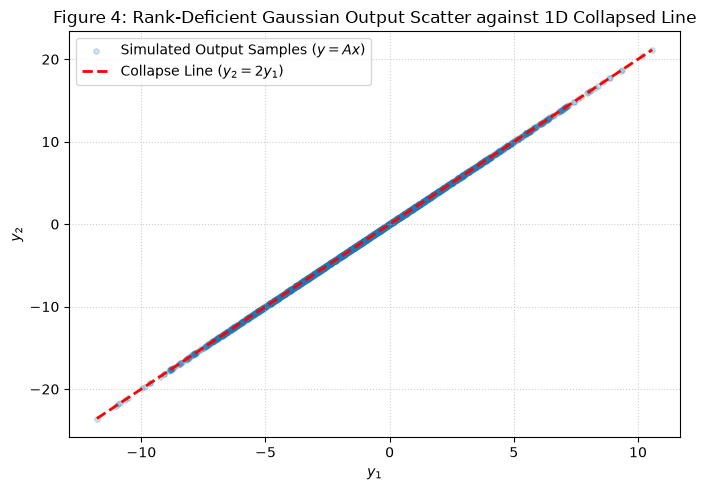

In [123]:
# Figure 4 generation

fig4 = plt.figure(figsize=(7, 5))
subset = Y2[:2000]
plt.scatter(subset[:, 0], subset[:, 1], alpha=0.2, s=15, label="Simulated Output Samples ($y = Ax$)")

# Plot the collapse line y2 = 2*y1
x_line = np.linspace(subset[:, 0].min(), subset[:, 0].max(), 100)
plt.plot(x_line, 2 * x_line, color="red", linestyle="--", linewidth=2, label="Collapse Line ($y_2 = 2y_1$)")

plt.title("Figure 4: Rank-Deficient Gaussian Output Scatter against 1D Collapsed Line")
plt.xlabel("$y_1$")
plt.ylabel("$y_2$")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
# plt.close(fig4)

## Step 5

## Step 6

## Step 7

## The Conditional Gaussian

### Part 1:

With mean zero and Σ = [[4, 2], [2, 4]]: det Σ = 12 and Σ⁻¹ = (1/12)[[4, -2], [-2, 4]].

The exponent of the joint density is
$$-\tfrac12 \mathbf v^T\Sigma^{-1}\mathbf v = -\tfrac16\,(x^2 - xy + y^2).$$

Complete the square in y:
$$x^2 - xy + y^2 = \left(y - \tfrac{x}{2}\right)^2 + \tfrac34 x^2 .$$

So the joint density factors into a piece with only x and a piece with y:
$$f_{XY}(x,y) = \underbrace{\frac{1}{\sqrt{2\pi\cdot 4}}e^{-x^2/8}}_{f_X(x),\ X\sim N(0,4)} \cdot \frac{1}{\sqrt{2\pi\cdot 3}}\exp\!\left(-\frac{(y-x/2)^2}{2\cdot 3}\right).$$

Dividing by $f_X(x)$ gives
$$Y \mid X=x \sim N(0.5\,x,\ 3).$$
It is Gaussian, the mean is linear in x, and the variance does not depend on x.


### Part 2: 
For a partitioned Gaussian vector with blocks a and b:
$$\mu_{a|b} = \mu_a + \Sigma_{ab}\Sigma_{bb}^{-1}(x_b-\mu_b), \qquad
\Sigma_{a|b} = \Sigma_{aa} - \Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}.$$

Here a = Y, b = X, so $\Sigma_{aa}=4$, $\Sigma_{ab}=2$, $\Sigma_{bb}=4$:
$$\mu_{Y|X} = \tfrac{2}{4}x = 0.5x, \qquad \sigma^2_{Y|X} = 4 - \tfrac{2\cdot 2}{4} = 3.$$
This matches Part 1.

Binned slope = 0.4998 +/- 0.0009  (analytic 0.5, 0.26 SE away)
Raw slope    = 0.5013 +/- 0.0009
Bins used: 40
Conditional variance: mean of bins = 3.0081, min = 2.941, max = 3.171  (analytic 3)


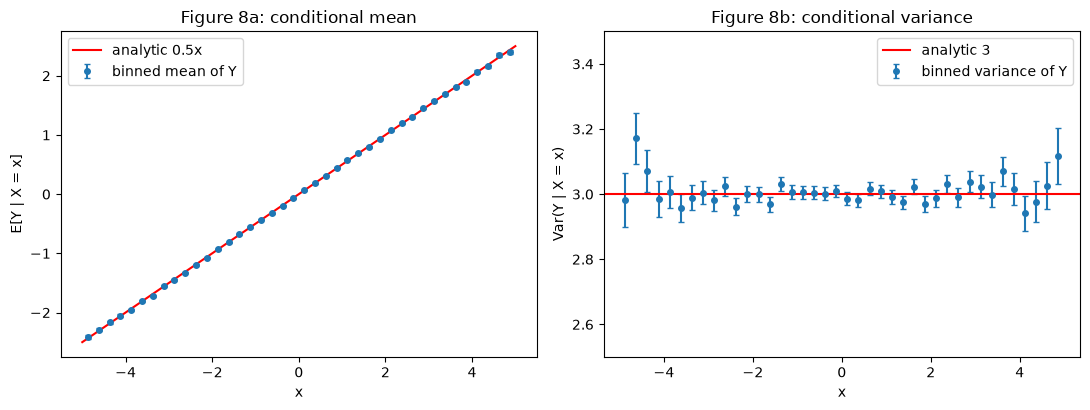

In [ ]:
Sigma = np.array([[4.0, 2.0], [2.0, 4.0]])
N = 10**6
samples = rng_7.multivariate_normal([0, 0], Sigma, size=N)
x, y = samples[:, 0], samples[:, 1]

# Parts 3 and 4: bin by x, then get the mean and variance of y in each bin
edges = np.linspace(-5, 5, 41)           # 40 bins, width 0.25
bin_x, bin_mean, bin_var, se_mean, se_var = [], [], [], [], []

for k in range(40):
    in_bin = (x >= edges[k]) & (x < edges[k + 1])
    n = in_bin.sum()
    if n < 200:                           # skip bins with too few samples
        continue
    yb = y[in_bin]
    v = yb.var(ddof=1)
    bin_x.append(x[in_bin].mean())        # use the average x in the bin, not the bin center
    bin_mean.append(yb.mean())
    bin_var.append(v)
    se_mean.append(np.sqrt(v / n))        # standard error of a mean
    se_var.append(v * np.sqrt(2 / (n - 1)))   # standard error of a variance (Gaussian data)

bin_x, bin_mean, bin_var = np.array(bin_x), np.array(bin_mean), np.array(bin_var)
se_mean, se_var = np.array(se_mean), np.array(se_var)

# slope of the binned means, plus a check using all the raw samples
fit_bins = stats.linregress(bin_x, bin_mean)
fit_raw = stats.linregress(x, y)
z_slope = (fit_bins.slope - 0.5) / fit_bins.stderr

print(f"Binned slope = {fit_bins.slope:.4f} +/- {fit_bins.stderr:.4f}  (analytic 0.5, {abs(z_slope):.2f} SE away)")
print(f"Raw slope    = {fit_raw.slope:.4f} +/- {fit_raw.stderr:.4f}")
print(f"Bins used: {len(bin_x)}")
print(f"Conditional variance: mean of bins = {bin_var.mean():.4f}, "
      f"min = {bin_var.min():.3f}, max = {bin_var.max():.3f}  (analytic 3)")

# Figure 8
xx = np.linspace(-5, 5, 100)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].errorbar(bin_x, bin_mean, yerr=se_mean, fmt="o", ms=4, capsize=2, label="binned mean of Y")
ax[0].plot(xx, 0.5 * xx, "r-", label="analytic 0.5x")
ax[0].set_xlabel("x"); ax[0].set_ylabel("E[Y | X = x]")
ax[0].set_title("Figure 8a: conditional mean"); ax[0].legend()

ax[1].errorbar(bin_x, bin_var, yerr=se_var, fmt="o", ms=4, capsize=2, label="binned variance of Y")
ax[1].axhline(3, color="r", label="analytic 3")
ax[1].set_ylim(2.5, 3.5)
ax[1].set_xlabel("x"); ax[1].set_ylabel("Var(Y | X = x)")
ax[1].set_title("Figure 8b: conditional variance"); ax[1].legend()
plt.tight_layout(); plt.show()

### Part 5: 

The estimator with the smallest mean squared error among *all* functions of $X$, linear or not, is the
conditional mean $E[Y\mid X]$. For jointly Gaussian data, Part 1 shows this conditional mean is
$0.5\,x$, which is already a linear function of $x$. So the best linear estimator and the best possible
estimator coincide, and no nonlinear function can beat the linear one. For non-Gaussian data this fails. In
Step 2, $Y=X^2$ is perfectly predictable from $X$ by a nonlinear function while the best linear
estimator is useless, because the correlation is zero. Because the conditional variance is also constant, the
achieved error is the same for every observed $x$. It equals $\Sigma_{a|b}=\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}$,
which is exactly the MMSE expression $\sigma_s^2-\Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}$ we use in Step 8.

## Step 8

### Part 1: 
Each sensor reads $X_i = S + N_i$, and $S$ is independent of the noise. So

$$\Sigma_{xx} = \sigma_s^2\,\mathbf 1\mathbf 1^T + \Sigma_N =
\begin{bmatrix}5 & 4+c\\ 4+c & 6\end{bmatrix},
\qquad
\Sigma_{sx} = \begin{bmatrix}4\\4\end{bmatrix}.$$

$\Sigma_{sx}$ is $[4,4]^T$ because $\text{Cov}(S, X_i)=\text{Cov}(S,S)=4$, and the noise adds nothing.

### Part 2: 
For $\hat S = \mathbf w^T\mathbf X$, the mean squared error is
$$E[(S-\mathbf w^T\mathbf X)^2] = \sigma_s^2 - 2\mathbf w^T\Sigma_{sx} + \mathbf w^T\Sigma_{xx}\mathbf w.$$
Setting the gradient to zero gives $\Sigma_{xx}\mathbf w = \Sigma_{sx}$, so
$$\mathbf w = \Sigma_{xx}^{-1}\Sigma_{sx}, \qquad \text{MMSE} = \sigma_s^2 - \Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}.$$

### Part 3: 
$\Sigma_N=\begin{bmatrix}1&c\\c&2\end{bmatrix}$ is positive definite when $1>0$ and $\det\Sigma_N = 2-c^2 > 0$.
So $|c| < \sqrt2 \approx 1.414$.

### Part 5: 

Multiplying $\Sigma_{xx}^{-1}$ by $\Sigma_{sx}=[4,4]^T$:
$$w_1=\frac{4(2-c)}{14-8c-c^2},\qquad w_2=\frac{4(1-c)}{14-8c-c^2}=\frac{4(1-c)}{30-(4+c)^2}.$$
The denominator is positive for all admissible $c$, so the sign of $w_2$ is the sign of $(1-c)$. It is zero exactly at $c=1$ and negative for $c>1$.

For the MMSE, $\Sigma_{sx}^T\mathbf w=4(w_1+w_2)=\dfrac{16(3-2c)}{14-8c-c^2}$, so
$$\text{MMSE}(c)=4-\frac{16(3-2c)}{14-8c-c^2}=\frac{4(14-8c-c^2)-16(3-2c)}{14-8c-c^2}=\frac{4(2-c^2)}{14-8c-c^2}.$$

Differentiate with the quotient rule, with $N=8-4c^2$ and $D=14-8c-c^2$:
$$N'D-ND'=-8c(14-8c-c^2)-(8-4c^2)(-8-2c)=32c^2-96c+64=32(c-1)(c-2).$$
$$\frac{d\,\text{MMSE}}{dc}=\frac{32(c-1)(c-2)}{(14-8c-c^2)^2}.$$
This is zero at $c=1$ (the root $c=2$ is outside the admissible range). For $c<1$ both factors are negative, so the derivative is positive. For $1<c<\sqrt2$ it is negative. The derivative changes from $+$ to $-$, so $c=1$ is a **maximum**, not a minimum. At $c=1$ the MMSE is $4/5=0.8$, which equals the best single sensor.

    c         w1         w2       MMSE  best 1 sensor  equal (avg)
 -1.4   0.585198   0.413081   0.006885       0.800000     0.050000
 -1.0   0.571429   0.380952   0.190476       0.800000     0.250000
 -0.5   0.563380   0.338028   0.394366       0.800000     0.500000
  0.0   0.571429   0.285714   0.571429       0.800000     0.750000
  0.5   0.615385   0.205128   0.717949       0.800000     1.000000
  1.0   0.800000   0.000000   0.800000       0.800000     1.250000
  1.2   1.081081  -0.270270   0.756757       0.800000     1.350000
  1.4   2.857143  -1.904762   0.190476       0.800000     1.450000

Max |w2 numeric - closed form| = 1.44e-14
Max |MMSE numeric - closed form| = 5.77e-15
MMSE(0.99) = 0.799937, MMSE(1) = 0.800000, MMSE(1.01) = 0.799935
Largest MMSE on the grid = 0.799996 at c = 1.002
MMSE(-1) = 0.190476, MMSE(1.4) = 0.190476


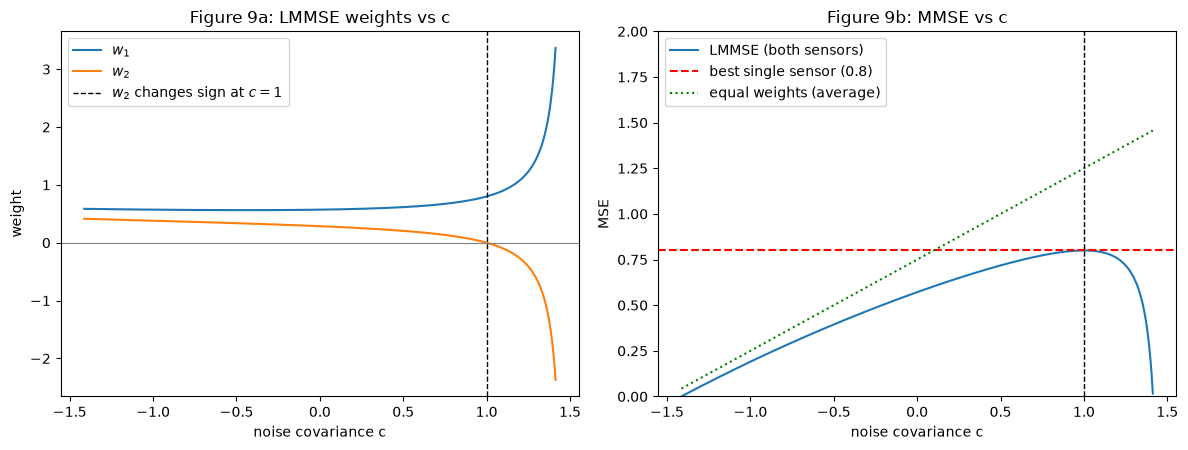

c = 0.8: simulated MSE = 0.78036 +/- 0.00110, analytic = 0.78161, difference = -0.00125 (1.13 SE)
c = 1.4: simulated MSE = 0.19080 +/- 0.00027, analytic = 0.19048, difference = +0.00032 (1.20 SE)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sig2 = 4.0
ones = np.ones(2)
Sigma_sx = sig2 * ones                       # [4, 4]

def sigma_N(c):
    return np.array([[1.0, c], [c, 2.0]])

def sigma_xx(c):
    return sig2 * np.outer(ones, ones) + sigma_N(c)

def lmmse(c):
    w = ml.lmmse_weights(sigma_xx(c), Sigma_sx)
    return w, sig2 - Sigma_sx @ w            # weights, MMSE

def mse_of(w, c):
    # S - w^T X = S(1 - sum w) - w^T N, so the error variance is:
    return sig2 * (1 - w.sum())**2 + w @ sigma_N(c) @ w

best_single = min(sig2 * 1 / (sig2 + 1), sig2 * 2 / (sig2 + 2))   # sensor 1 alone = 0.8

# Part 4: table
c_list = [-1.4, -1.0, -0.5, 0.0, 0.5, 1.0, 1.2, 1.4]
print(f"{'c':>5} {'w1':>10} {'w2':>10} {'MMSE':>10} {'best 1 sensor':>14} {'equal (avg)':>12}")
for c in c_list:
    w, m = lmmse(c)
    eq = mse_of(np.array([0.5, 0.5]), c)
    print(f"{c:5.1f} {w[0]:10.6f} {w[1]:10.6f} {m:10.6f} {best_single:14.6f} {eq:12.6f}")

# Part 5: check closed forms against the numerical solve over the whole range
cs = np.linspace(-np.sqrt(2) + 1e-3, np.sqrt(2) - 1e-3, 400)
W = np.array([lmmse(c)[0] for c in cs])
M = np.array([lmmse(c)[1] for c in cs])
den = 14 - 8 * cs - cs**2
err_w2 = np.max(np.abs(W[:, 1] - 4 * (1 - cs) / den))
err_m = np.max(np.abs(M - 4 * (2 - cs**2) / den))
print(f"\nMax |w2 numeric - closed form| = {err_w2:.2e}")
print(f"Max |MMSE numeric - closed form| = {err_m:.2e}")
print(f"MMSE(0.99) = {lmmse(0.99)[1]:.6f}, MMSE(1) = {lmmse(1.0)[1]:.6f}, MMSE(1.01) = {lmmse(1.01)[1]:.6f}")
print(f"Largest MMSE on the grid = {M.max():.6f} at c = {cs[M.argmax()]:.3f}")
print(f"MMSE(-1) = {lmmse(-1.0)[1]:.6f}, MMSE(1.4) = {lmmse(1.4)[1]:.6f}")

# Figure 9
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].plot(cs, W[:, 0], label="$w_1$")
ax[0].plot(cs, W[:, 1], label="$w_2$")
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].axvline(1, color="k", ls="--", lw=1, label="$w_2$ changes sign at $c=1$")
ax[0].set_xlabel("noise covariance c"); ax[0].set_ylabel("weight")
ax[0].set_title("Figure 9a: LMMSE weights vs c"); ax[0].legend()

ax[1].plot(cs, M, label="LMMSE (both sensors)")
ax[1].axhline(best_single, color="r", ls="--", label="best single sensor (0.8)")
ax[1].plot(cs, [mse_of(np.array([0.5, 0.5]), c) for c in cs], color="g", ls=":", label="equal weights (average)")
ax[1].axvline(1, color="k", ls="--", lw=1)
ax[1].set_ylim(0, 2)
ax[1].set_xlabel("noise covariance c"); ax[1].set_ylabel("MSE")
ax[1].set_title("Figure 9b: MMSE vs c"); ax[1].legend()
plt.tight_layout(); plt.show()

# Part 9: Monte Carlo at c = 0.8 and c = 1.4
N8 = 10**6
mc = {}
for c in [0.8, 1.4]:
    w, m = lmmse(c)
    S = np.sqrt(sig2) * rng_8.standard_normal(N8)
    noise = rng_8.multivariate_normal([0, 0], sigma_N(c), size=N8)
    X = S[:, None] + noise
    e2 = (S - X @ w)**2
    mc[c] = (e2.mean(), e2.std(ddof=1) / np.sqrt(N8), m)
    print(f"c = {c}: simulated MSE = {mc[c][0]:.5f} +/- {mc[c][1]:.5f}, analytic = {m:.5f}, "
          f"difference = {mc[c][0] - m:+.5f} ({abs(mc[c][0] - m) / mc[c][1]:.2f} SE)")

In [3]:
m0 = lmmse(0.0)[1]
m14 = lmmse(1.4)[1]
w14 = lmmse(1.4)[0]
var_diff = 1 + 2 - 2 * 1.4          # Var(X1 - X2) = Var(N1 - N2) = 1 + 2 - 2c

display(Markdown(f"""
**Part 4 (table).** Both-sensor LMMSE is never worse than the best single sensor ({best_single:.3f}) or the
plain average. At c = 0 the MMSE is {m0:.4f}. The two baselines only match the optimum at c = 1.

**Part 5 (c = 1).** The numerical weights match the closed forms (max difference {err_w2:.1e} for w2 and
{err_m:.1e} for the MMSE). At c = 1, w2 = 0 and the MMSE is {lmmse(1.0)[1]:.4f}, the same as sensor 1
alone. The MMSE just below and just above c = 1 is {lmmse(0.99)[1]:.5f} and {lmmse(1.01)[1]:.5f}, both
below {lmmse(1.0)[1]:.5f}, so c = 1 is a **maximum** of the MMSE, not a minimum. This is because
Cov(N1, N2 - N1) = c - 1 = 0 at c = 1. The difference X2 - X1 = N2 - N1 then has nothing to do with N1, and
it contains no S, so sensor 2 adds no usable information.

**Part 6 (negative weight).** For c > 1 the estimator uses X1 - X2 = N1 - N2, which contains no S at all, only
noise. Its variance is 3 - 2c, which is {var_diff:.2f} at c = 1.4, so it is a very precise reading of
N1 - N2. Since Cov(N1, N1 - N2) = 1 - c is negative, learning N1 - N2 tells us the noise in sensor 1,
and we subtract that noise off. The weights at c = 1.4 are w = [{w14[0]:.4f}, {w14[1]:.4f}]. The estimator
is not subtracting a measurement of S, it is subtracting a measurement of the noise.

**Part 7.** The MMSE is {m0:.4f} at c = 0 and {m14:.4f} at c = 1.4, a drop of
{(1 - m14 / m0) * 100:.0f} percent. Correlated noise helps because the noise is shared. When the two noises
move together, the difference of the readings cancels S and isolates the noise, which gives us a way to remove it.
Independent noise gives us no such handle.

**Part 8 (shape of the curve).** The MMSE rises from near 0 at c = -sqrt(2) up to its largest value, {M.max():.4f},
at c = 1, then falls back toward 0 as c goes to +sqrt(2). So c = 1 is the worst admissible c, the one
point where the second sensor is useless. At both ends of the range the noises are perfectly correlated
(N2 = plus or minus sqrt(2) N1), so the noise can be cancelled exactly and the MMSE goes to 0.
The values are also not symmetric: MMSE(-1) and MMSE(1.4) are both {lmmse(1.4)[1]:.4f}.

**Part 9 (Monte Carlo).** At c = 0.8 the simulated MSE is {mc[0.8][0]:.4f} ± {mc[0.8][1]:.4f} against an
analytic {mc[0.8][2]:.4f}. At c = 1.4 it is {mc[1.4][0]:.4f} ± {mc[1.4][1]:.4f} against {mc[1.4][2]:.4f}.
Both agree within about {max(abs(mc[0.8][0]-mc[0.8][2])/mc[0.8][1], abs(mc[1.4][0]-mc[1.4][2])/mc[1.4][1]):.1f} standard errors.
"""))


**Part 4 (table).** Both-sensor LMMSE is never worse than the best single sensor (0.800) or the
plain average. At c = 0 the MMSE is 0.5714. The two baselines only match the optimum at c = 1.

**Part 5 (c = 1).** The numerical weights match the closed forms (max difference 1.4e-14 for w2 and
5.8e-15 for the MMSE). At c = 1, w2 = 0 and the MMSE is 0.8000, the same as sensor 1
alone. The MMSE just below and just above c = 1 is 0.79994 and 0.79993, both
below 0.80000, so c = 1 is a **maximum** of the MMSE, not a minimum. This is because
Cov(N1, N2 - N1) = c - 1 = 0 at c = 1. The difference X2 - X1 = N2 - N1 then has nothing to do with N1, and
it contains no S, so sensor 2 adds no usable information.

**Part 6 (negative weight).** For c > 1 the estimator uses X1 - X2 = N1 - N2, which contains no S at all, only
noise. Its variance is 3 - 2c, which is 0.20 at c = 1.4, so it is a very precise reading of
N1 - N2. Since Cov(N1, N1 - N2) = 1 - c is negative, learning N1 - N2 tells us the noise in sensor 1,
and we subtract that noise off. The weights at c = 1.4 are w = [2.8571, -1.9048]. The estimator
is not subtracting a measurement of S, it is subtracting a measurement of the noise.

**Part 7.** The MMSE is 0.5714 at c = 0 and 0.1905 at c = 1.4, a drop of
67 percent. Correlated noise helps because the noise is shared. When the two noises
move together, the difference of the readings cancels S and isolates the noise, which gives us a way to remove it.
Independent noise gives us no such handle.

**Part 8 (shape of the curve).** The MMSE rises from near 0 at c = -sqrt(2) up to its largest value, 0.8000,
at c = 1, then falls back toward 0 as c goes to +sqrt(2). So c = 1 is the worst admissible c, the one
point where the second sensor is useless. At both ends of the range the noises are perfectly correlated
(N2 = plus or minus sqrt(2) N1), so the noise can be cancelled exactly and the MMSE goes to 0.
The values are also not symmetric: MMSE(-1) and MMSE(1.4) are both 0.1905.

**Part 9 (Monte Carlo).** At c = 0.8 the simulated MSE is 0.7804 ± 0.0011 against an
analytic 0.7816. At c = 1.4 it is 0.1908 ± 0.0003 against 0.1905.
Both agree within about 1.2 standard errors.


### Part 10: 

I would pick the correlated-noise pair, as long as c is not close to 1. Shared interference can be cancelled
by comparing the two sensors, and the benefit grows as the correlation gets stronger. The catch is that the
weights depend on knowing the noise covariance accurately. Near the ends of the range the weight on sensor 2
is large (w2 = -1.9 at c = 1.4), so a small error in c causes a large error in the estimate. I would measure
the noise covariance with no signal present and re-measure it if temperature or power conditions change.

## Bonus A

## Bonus B

In [4]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")

Total Notebook Runtime: 9.789 seconds
